# Notebook 11 (Revised) — Neural forecasting with LSTM and TCN

## Purpose

This notebook compares LSTM and Temporal Convolutional Network (TCN) models for predicting SOLETE solar PV power 15, 30 and 60 minutes ahead. The models use the forecasting dataset and temporal-validation rules established in Notebooks 09 and 10. The revised experiments are kept separate from the historical `11_deep_learning_models.ipynb`.

Two questions guide the experiment: how do LSTM and TCN perform at the three forecast horizons, and do the extra astronomical and Panchang features improve on the earlier feature sets? We compare five nested feature families (F0–F4) and four fixed model configurations (C1–C4) per architecture.

The experiment is complete: **360 development-CV evaluations have been archived** (2 models × 3 horizons × 5 feature families × 4 configurations × 3 folds). The analysis at the end of this notebook checks those records and summarizes the results. All model-training switches remain off; running the notebook again must not retrain the models.

## Experimental rules

- **Forecast issue time $t$:** measurements are available up to this time. The target is the PV power at $t+h$, where $h$ is 15, 30 or 60 minutes.
- **Input history:** 13 observations at five-minute intervals, covering the preceding hour through $t$. Nine measured variables are used in the sequence branch. The other features enter a separate auxiliary branch.
- **Validation:** three expanding-window folds, in chronological order. A 60-minute gap prevents labels that would not yet be available from entering training.
- **Model fitting:** an inner chronological validation split chooses the number of training epochs. A fresh model is then fitted on the corresponding outer training fold. Each candidate is evaluated on the outer validation fold.
- **Comparison:** the unweighted mean of the three outer-fold MAEs, reported in kW, determines the development ranking; configuration order breaks ties.
- **Protected test period:** June–August 2019, comprising 26,496 rows. It is excluded from development CV and is **not evaluated in this notebook**.

F0 checkpoints use the original V1 preprocessing. F1–F4 use V2 preprocessing, which handles a constant training-year feature without using validation data. These policies are fixed and recorded separately. The pilot experiments and single-fold feasibility checks below are historical setup checks, not results used to choose the final model.

**Reproducing the notebook:** open it from the project root or `notebooks/` using the project's `.venv`. The local SOLETE data, JPL ephemeris, reference notebooks, `src/` modules and archived JSON checkpoints are required. With the training switches left as saved, **Restart Kernel + Run All** reconstructs the inputs and produces the development-CV tables without new neural fits.

## 1. Reconstructing the forecasting data

The following cells use the same construction rules as revised Notebook 10. Before building the modelling tables, the code checks the recorded source hashes of Notebook 09. This prevents a later change to the reference feature definitions from silently changing the neural experiment.

In [1]:
# Restart-safe, read-only project bootstrap. Run FIRST after a kernel restart.
# Notebook cells do not inherit the VS Code terminal's import path reliably.
import os
import sys
from pathlib import Path

_startup_cwd = Path.cwd().resolve()
_explicit_root = os.environ.get("SOLETE_PROJECT_ROOT")
_search_bases = []
if _explicit_root:
    _search_bases.append(Path(_explicit_root).expanduser())
_search_bases.append(_startup_cwd)
for _key in ("VSCODE_CWD", "PWD"):
    if os.environ.get(_key):
        _search_bases.append(Path(os.environ[_key]).expanduser())

_root_candidates = []
for _base in _search_bases:
    _base = _base.resolve()
    for _folder in (_base, *_base.parents):
        _root_candidates.append(_folder)
    # VS Code can open the parent directory instead of the repository itself.
    _root_candidates.extend((_base / "Project", _base / "solete-lunisolar-forecasting"))

PROJECT_ROOT = next((
    _folder for _folder in dict.fromkeys(_root_candidates)
    if (_folder / "src" / "revised_neural_campaign.py").is_file()
    and (_folder / "notebooks" / "09_modelling_dataset_and_protocol.ipynb").is_file()
), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the SOLETE repository from this Jupyter kernel. "
        "Open the repository folder in VS Code and select its .venv kernel; "
        "or set the SOLETE_PROJECT_ROOT environment variable to the repository "
        "directory before starting the kernel. "
        f"Jupyter started in: {_startup_cwd}"
    )
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Original canonical notebook construction expects cwd to be repo/notebooks.
# Standardize at the repo root so its unchanged source code finds its inputs.
os.chdir(PROJECT_ROOT)
from src.revised_neural_batch_v2 import read_mixed_progress

_boot_v1 = PROJECT_ROOT / "results/development_only/revised_neural_cv_v1"
_boot_v2 = PROJECT_ROOT / "results/development_only/revised_neural_cv_v2_year_std1"
_boot_progress = read_mixed_progress(_boot_v1, _boot_v2)
print("NOTEBOOK 11 RESTART-SAFE IMPORT BOOTSTRAP: PASSED")
print("Python:", sys.executable)
print("Repository:", PROJECT_ROOT)
print("Existing development-CV checkpoints:", len(_boot_progress), "/ 360")
print("No training or terminal evaluation performed")


NOTEBOOK 11 RESTART-SAFE IMPORT BOOTSTRAP: PASSED
Python: /Users/siddharthgupta/Downloads/NSUT/Semester 1/MTITC102 AI and Machine Learning/Project/.venv/bin/python
Repository: /Users/siddharthgupta/Downloads/NSUT/Semester 1/MTITC102 AI and Machine Learning/Project
Existing development-CV checkpoints: 360 / 360
No training or terminal evaluation performed


In [2]:
from pathlib import Path
import hashlib
import json

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
REFERENCE_NOTEBOOK = PROJECT_ROOT / "notebooks" / "09_modelling_dataset_and_protocol.ipynb"

# Canonical construction: the first FIVE code cells in Notebook 09 at
# validated project commit 369a9d9.  Do not permit silent code drift.
NOTEBOOK09_CODE_SHA256 = (
    "18d232021455524939be8e14fc67842819ea4b8701a41a279b8997a47768bbee",
    "6add41c3649cfd7300a1fa04e0a966f30f7fc78c2a4b4bbaa054056358ddc21b",
    "724b7cdf9cd01790c9a0c9371967ff1c264c0f0d9730d1ef8d9be30dd359456d",
    "303947573618f2bcc5c280e2dd6e2d392805dc194073d51a8e4c84c7b4f3a373",
    "58ab56827f81c210df0ec662208f217baa3043d22c1940b028b041407efa9f09",
)

if not REFERENCE_NOTEBOOK.is_file():
    raise FileNotFoundError(f"Cannot find canonical Notebook 09: {REFERENCE_NOTEBOOK}")
with REFERENCE_NOTEBOOK.open(encoding="utf-8") as handle:
    _reference = json.load(handle)
reference_code_cells = [
    "".join(cell.get("source", []))
    for cell in _reference["cells"]
    if cell["cell_type"] == "code"
]
actual_hashes = tuple(
    hashlib.sha256(source.encode("utf-8")).hexdigest()
    for source in reference_code_cells[:5]
)
if actual_hashes != NOTEBOOK09_CODE_SHA256:
    raise RuntimeError(
        "Notebook 09 canonical construction source changed since commit 369a9d9. "
        "Stop: review and resynchronize the revised Notebook 10 instead of "
        "training with mismatched feature definitions."
    )
print("Canonical Notebook 09 source hash parity: PASSED (5 construction cells)")
print("Notebook 09 source: read-only")


Canonical Notebook 09 source hash parity: PASSED (5 construction cells)
Notebook 09 source: read-only


In [3]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import swisseph as swe
from IPython.display import display

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_solete
from src.preprocessing import (
    build_cleaned_solete_features,
    build_gregorian_features,
)
import src.astronomy_features as astronomy_features
import src.vedic_calendar as vedic_calendar
from src.astronomy_features import (
    build_lunar_f3_features,
    build_solar_f2_features,
    load_jpl_ephemeris,
    solete_astronomy_reference_times,
    tropical_longitudes_for_solete,
)
from src.vedic_calendar import (
    build_panchang_f4_raw,
    lahiri_ayanamsha_for_utc_times,
)
from src.feature_families import (
    encode_panchang_fixed_vocabulary,
    PANCHANG_INDICATOR_COUNT,
)

DATA_5MIN = PROJECT_ROOT / "solete_dataset" / "SOLETE_Pombo_5min.h5"
EPHEMERIS_FILE = PROJECT_ROOT / "ephemeris" / "de440s.bsp"

for path in [DATA_5MIN, EPHEMERIS_FILE]:
    if not path.exists():
        raise FileNotFoundError(path)

# ------------------------------------------------------------------
# Source-parity guard.
#
# Notebook 07 froze pvlib altitude=0 m and delta_t=None.
# Notebook 08 froze standard Lahiri with FLG_NONUT.
#
# Stop immediately if reusable source files still implement the older
# conventions. A source-sync helper is supplied alongside this notebook.
# ------------------------------------------------------------------

if not hasattr(
    astronomy_features,
    "SOLETE_SOLAR_ALTITUDE_CONVENTION_M",
):
    raise RuntimeError(
        "src/astronomy_features.py is older than revised Notebook 07. "
        "Apply the supplied source-sync helper before running Notebook 09."
    )

assert astronomy_features.SOLETE_SOLAR_ALTITUDE_CONVENTION_M == 0.0

assert (
    vedic_calendar.LAHIRI_AYANAMSHA_FLAGS
    & swe.FLG_NONUT
), (
    "src/vedic_calendar.py still uses the older nutation-included "
    "Lahiri convention. Apply the supplied source-sync helper first."
)

df_raw = load_solete(DATA_5MIN).sort_index()

assert df_raw.index.is_monotonic_increasing
assert not df_raw.index.has_duplicates
assert df_raw.index.tz is not None

expected_step = pd.Timedelta(minutes=5)
observed_steps = df_raw.index.to_series().diff().dropna()
assert (observed_steps == expected_step).all(), (
    "SOLETE modelling timeline is not a complete 5-minute grid."
)

print("SOLETE:", df_raw.shape)
print("Period:", df_raw.index.min(), "to", df_raw.index.max())
print("Astronomy offset:", astronomy_features.SOLETE_ASTRONOMY_OFFSET)
print("Solar altitude convention [m]:",
      astronomy_features.SOLETE_SOLAR_ALTITUDE_CONVENTION_M)
print("Lahiri flags:", vedic_calendar.LAHIRI_AYANAMSHA_FLAGS)


SOLETE: (131617, 11)
Period: 2018-06-01 00:00:00+00:00 to 2019-09-01 00:00:00+00:00
Astronomy offset: 0 days 00:02:00
Solar altitude convention [m]: 0.0
Lahiri flags: 66


In [4]:
RESOLUTION_MINUTES = 5
FORECAST_HORIZONS = {
    15: 3,
    30: 6,
    60: 12,
}

PRIMARY_TARGET = "P_Solar[kW]"

F0_HISTORY_SOURCES = {
    "P_Solar_kw": "P_Solar[kW]",
    "GHI_kw1m2": "GHI[kW1m2]",
    "POA_Irr_kw1m2": "POA Irr[kW1m2]",
    "temperature_degC": "TEMPERATURE[degC]",
    "humidity_clean": "Humidity_clean",
    "pressure_clean_mbar": "Pressure_clean[mbar]",
    "wind_speed_m1s": "WIND_SPEED[m1s]",
    "wind_direction_sin": "wind_direction_sin",
    "wind_direction_cos": "wind_direction_cos",
}

RECENT_LAGS = tuple(range(13))
DAILY_LAG_STEPS = 24 * 60 // RESOLUTION_MINUTES

assert DAILY_LAG_STEPS == 288

df_clean = build_cleaned_solete_features(df_raw)

required_f0_sources = list(F0_HISTORY_SOURCES.values())
assert not df_clean[required_f0_sources].isna().any().any()

# F0: nine channels at t,t-5,...,t-60 plus P_Solar(t-24h).
f0_columns = {}

for feature_name, source_column in F0_HISTORY_SOURCES.items():
    for lag in RECENT_LAGS:
        f0_columns[f"{feature_name}_lag_{lag}"] = (
            df_clean[source_column].shift(lag)
        )

f0_columns["P_Solar_kw_issue_minus_24h"] = (
    df_clean[PRIMARY_TARGET].shift(DAILY_LAG_STEPS)
)

df_f0_full = pd.DataFrame(f0_columns, index=df_clean.index)

assert df_f0_full.shape[1] == 118

first_complete_f0_issue = df_f0_full.dropna().index.min()
expected_first_complete_f0_issue = pd.Timestamp(
    "2018-06-02 00:00:00",
    tz="UTC",
)
assert first_complete_f0_issue == expected_first_complete_f0_issue

print("F0 full-timeline shape:", df_f0_full.shape)
print("First row with complete F0:", first_complete_f0_issue)


F0 full-timeline shape: (131617, 118)
First row with complete F0: 2018-06-02 00:00:00+00:00


In [5]:
STUDY_START = pd.Timestamp("2018-06-01 00:00:00", tz="UTC")
LOCKED_TEST_START = pd.Timestamp("2019-06-01 00:00:00", tz="UTC")
STUDY_END = pd.Timestamp("2019-09-01 00:00:00", tz="UTC")

base_modelling_tables = {}

for horizon_minutes, horizon_steps in FORECAST_HORIZONS.items():
    table = df_f0_full.copy()

    table["issue_time"] = table.index
    table["valid_time"] = (
        table["issue_time"]
        + pd.Timedelta(minutes=horizon_minutes)
    )
    table["target_P_Solar_kW"] = (
        df_clean[PRIMARY_TARGET].shift(-horizon_steps)
    )
    table["horizon_minutes"] = horizon_minutes

    usable = (
        table[df_f0_full.columns].notna().all(axis=1)
        & table["target_P_Solar_kW"].notna()
        & table["valid_time"].ge(STUDY_START)
        & table["valid_time"].lt(STUDY_END)
    )

    table = table.loc[usable].copy()

    table["final_partition"] = np.where(
        table["valid_time"] < LOCKED_TEST_START,
        "development",
        "locked_test",
    )

    # Direct target-alignment verification.
    sample_positions = np.linspace(
        0, len(table) - 1, 5, dtype=int
    )
    for position in sample_positions:
        valid_time = table["valid_time"].iloc[position]
        observed = table["target_P_Solar_kW"].iloc[position]
        expected = df_clean.loc[valid_time, PRIMARY_TARGET]
        assert np.isclose(observed, expected, atol=0.0, rtol=0.0)

    base_modelling_tables[horizon_minutes] = table

population_summary = []

for horizon, table in base_modelling_tables.items():
    population_summary.append({
        "horizon_minutes": horizon,
        "rows": len(table),
        "development_rows":
            int(table["final_partition"].eq("development").sum()),
        "locked_test_rows":
            int(table["final_partition"].eq("locked_test").sum()),
        "first_issue": table["issue_time"].min(),
        "first_valid": table["valid_time"].min(),
        "last_valid": table["valid_time"].max(),
    })

display(pd.DataFrame(population_summary))


,horizon_minutes,rows,development_rows,locked_test_rows,first_issue,first_valid,last_valid
0,15,131325,104829,26496,2018-06-02 00:00:00+00:00,2018-06-02 00:15:00+00:00,2019-08-31 23:55:00+00:00
1,30,131322,104826,26496,2018-06-02 00:00:00+00:00,2018-06-02 00:30:00+00:00,2019-08-31 23:55:00+00:00
2,60,131316,104820,26496,2018-06-02 00:00:00+00:00,2018-06-02 01:00:00+00:00,2019-08-31 23:55:00+00:00


In [6]:
ephemeris = load_jpl_ephemeris(EPHEMERIS_FILE)

# F1: no astronomical offset.
df_f1_increment_full = build_gregorian_features(df_clean.index)
assert df_f1_increment_full.shape == (len(df_clean), 15)

# F2/F3: module applies row timestamp + 2 min.
df_f2_increment_full = build_solar_f2_features(df_clean.index)
df_f3_increment_full = build_lunar_f3_features(
    df_clean.index,
    ephemeris,
)

assert df_f2_increment_full.shape == (len(df_clean), 5)
assert df_f3_increment_full.shape == (len(df_clean), 9)

# F4 parents at the same +2 min astronomical reference.
df_tropical_full = tropical_longitudes_for_solete(
    df_clean.index,
    ephemeris,
)

astro_times = solete_astronomy_reference_times(df_clean.index)

ayanamsha = lahiri_ayanamsha_for_utc_times(astro_times)

df_ayanamsha = pd.Series(
    ayanamsha,
    index=df_clean.index,
    name="lahiri_ayanamsha_nonut_deg",
)

# Canonical Notebook 08 first-point guard.
KNOWN_FIRST_LAHIRI_NONUT = 24.11431760121269

assert np.isclose(
    df_ayanamsha.iloc[0],
    KNOWN_FIRST_LAHIRI_NONUT,
    atol=1e-10,
    rtol=0.0,
)

df_f4_raw_full = build_panchang_f4_raw(
    sun_tropical_longitude_deg=
        df_tropical_full["sun_tropical_longitude_deg"],
    moon_tropical_longitude_deg=
        df_tropical_full["moon_tropical_longitude_deg"],
    ayanamsha_deg=df_ayanamsha,
)

assert df_f4_raw_full.shape == (len(df_clean), 5)
assert not df_f4_raw_full.isna().any().any()

first_f4 = df_f4_raw_full.iloc[0]
assert int(first_f4["tithi"]) == 18
assert first_f4["paksha"] == "Krishna"
assert first_f4["karana"] == "Vanija"
assert first_f4["nakshatra"] == "Mula"
assert first_f4["yoga"] == "Shubha"

print("F1 increment:", df_f1_increment_full.shape)
print("F2 increment:", df_f2_increment_full.shape)
print("F3 increment:", df_f3_increment_full.shape)
print("Raw F4:", df_f4_raw_full.shape)
print("First Lahiri NONUT:", df_ayanamsha.iloc[0])
print("Notebook 07/08 source parity: PASSED")


F1 increment: (131617, 15)
F2 increment: (131617, 5)
F3 increment: (131617, 9)
Raw F4: (131617, 5)
First Lahiri NONUT: 24.11431760121269
Notebook 07/08 source parity: PASSED


In [7]:
EXPECTED_FEATURE_COUNTS = {
    "F0": 118,
    "F1": 133,
    "F2": 138,
    "F3": 147,
    "F4": 244,
}

assert PANCHANG_INDICATOR_COUNT == 97

feature_family_tables = {}
panchang_onehot_tables = {}

for horizon, base in base_modelling_tables.items():
    issue_index = base.index
    valid_index = pd.DatetimeIndex(
        base["valid_time"],
        name="valid_time",
    )

    f0 = df_f0_full.loc[issue_index].copy()

    f1_inc = df_f1_increment_full.loc[valid_index].copy()
    f1_inc.index = issue_index
    f1_inc = f1_inc.add_prefix("valid_")

    f2_inc = df_f2_increment_full.loc[valid_index].copy()
    f2_inc.index = issue_index
    f2_inc = f2_inc.add_prefix("valid_")

    f3_inc = df_f3_increment_full.loc[valid_index].copy()
    f3_inc.index = issue_index
    f3_inc = f3_inc.add_prefix("valid_")

    f4_raw = df_f4_raw_full.loc[valid_index].copy()
    f4_raw.index = issue_index
    f4_raw = f4_raw.add_prefix("valid_")

    f4_onehot = encode_panchang_fixed_vocabulary(f4_raw)

    assert f4_onehot.shape[1] == 97
    assert (f4_onehot.sum(axis=1) == 5).all()

    F0 = f0
    F1 = pd.concat([F0, f1_inc], axis=1)
    F2 = pd.concat([F1, f2_inc], axis=1)
    F3 = pd.concat([F2, f3_inc], axis=1)
    F4 = pd.concat([F3, f4_onehot], axis=1)

    families = {
        "F0": F0,
        "F1": F1,
        "F2": F2,
        "F3": F3,
        "F4": F4,
    }

    for family, table in families.items():
        assert table.index.equals(issue_index)
        assert table.shape[1] == EXPECTED_FEATURE_COUNTS[family]
        assert not table.isna().any().any()

    assert list(F1.columns[:118]) == list(F0.columns)
    assert list(F2.columns[:133]) == list(F1.columns)
    assert list(F3.columns[:138]) == list(F2.columns)
    assert list(F4.columns[:147]) == list(F3.columns)

    feature_family_tables[horizon] = families
    panchang_onehot_tables[horizon] = f4_onehot

print("Nested feature construction: PASSED")

for horizon, families in feature_family_tables.items():
    print(
        horizon,
        {name: table.shape for name, table in families.items()},
    )


Nested feature construction: PASSED
15 {'F0': (131325, 118), 'F1': (131325, 133), 'F2': (131325, 138), 'F3': (131325, 147), 'F4': (131325, 244)}
30 {'F0': (131322, 118), 'F1': (131322, 133), 'F2': (131322, 138), 'F3': (131322, 147), 'F4': (131322, 244)}
60 {'F0': (131316, 118), 'F1': (131316, 133), 'F2': (131316, 138), 'F3': (131316, 147), 'F4': (131316, 244)}


## 2. Checking features and time boundaries

The checks below compare target and lag calculations against the reference forecasting code. They also verify the feature-family columns, the temporal splits, and the exclusion of the 26,496-row test period. Passing these checks establishes that the neural models use the same forecasting problem as the classical models.

In [8]:
# Cross-check Notebook 09's independently written F0 and future-target
# calculations against the tested reusable forecasting protocol.
from src.forecasting_protocol import (
    F0_FEATURE_COLUMNS,
    FORECAST_HORIZONS as SOURCE_FORECAST_HORIZONS,
    build_base_modelling_tables as source_build_base,
    build_f0_history as source_build_f0,
    build_forecast_targets as source_build_targets,
)

assert FORECAST_HORIZONS == SOURCE_FORECAST_HORIZONS
source_f0 = source_build_f0(df_clean)
assert tuple(source_f0.columns) == F0_FEATURE_COLUMNS

# One known schema alias: both expressions mean P_Solar(issue_time - 24h).
# Do not silently relabel any other features.
source_f0 = source_f0.rename(
    columns={"P_Solar_kw_lag_288": "P_Solar_kw_issue_minus_24h"}
)
pd.testing.assert_frame_equal(source_f0, df_f0_full, check_exact=True)

source_targets = source_build_targets(df_clean)
source_base_tables = source_build_base(df_clean)
for horizon, base in base_modelling_tables.items():
    other = source_base_tables[horizon]
    assert base.index.equals(other.index), f"{horizon}: sample index mismatch"
    # Ignore only the two mutually incompatible *legacy* split metadata columns;
    # revised models use availability-safe CV masks below.
    compare_columns = list(df_f0_full.columns) + [
        "issue_time", "valid_time", "horizon_minutes", "target_P_Solar_kW"
    ]
    other_comparable = other.rename(
        columns={"P_Solar_kw_lag_288": "P_Solar_kw_issue_minus_24h"}
    )[compare_columns]
    pd.testing.assert_frame_equal(
        base[compare_columns], other_comparable, check_exact=True
    )
    pd.testing.assert_series_equal(
        base["target_P_Solar_kW"],
        source_targets[horizon].loc[base.index, "target_P_Solar_kW"],
        check_exact=True,
    )
print("F0 (118 columns) exact numerical/source parity: PASSED")
print("All horizon issue times, valid times and targets: PASSED")


F0 (118 columns) exact numerical/source parity: PASSED
All horizon issue times, valid times and targets: PASSED


In [9]:
# Independently RECOMPUTE deterministic increments at boundary-focused
# probe times. This detects wrong issue/valid alignment or category encoding
# without recomputing the full ephemeris three additional times.

def _compare_increment(actual, expected, *, discrete=False):
    pd.testing.assert_index_equal(actual.columns, expected.columns)
    assert actual.shape == expected.shape
    assert not actual.isna().any().any()
    assert not expected.isna().any().any()
    if discrete:
        pd.testing.assert_frame_equal(
            actual.reset_index(drop=True), expected.reset_index(drop=True),
            check_exact=True,
        )
    else:
        np.testing.assert_allclose(
            actual.to_numpy(dtype=np.float64),
            expected.to_numpy(dtype=np.float64),
            atol=1e-8, rtol=1e-10,
        )


_PROBE_BOUNDARIES = pd.DatetimeIndex([
    "2018-12-01 00:00:00+00:00",
    "2019-02-01 00:00:00+00:00",
    "2019-04-01 00:00:00+00:00",
    "2019-06-01 00:00:00+00:00",
    "2019-09-01 00:00:00+00:00",
])

probe_summary = []
for horizon, base in base_modelling_tables.items():
    all_valid = pd.DatetimeIndex(base["valid_time"])
    indices = {0, len(base) - 1}
    indices.update(np.linspace(0, len(base) - 1, num=17, dtype=int))
    for boundary in _PROBE_BOUNDARIES:
        position = int(all_valid.searchsorted(boundary))
        indices.update(p for p in (position - 1, position, position + 1)
                       if 0 <= p < len(base))
    positions = np.array(sorted(indices), dtype=int)
    issues = base.index[positions]
    valid = pd.DatetimeIndex(base["valid_time"].iloc[positions])
    families = feature_family_tables[horizon]

    greg = build_gregorian_features(valid).add_prefix("valid_")
    solar = build_solar_f2_features(valid).add_prefix("valid_")
    lunar = build_lunar_f3_features(valid, ephemeris).add_prefix("valid_")

    _compare_increment(
        families["F1"].loc[issues, greg.columns], greg
    )
    _compare_increment(
        families["F2"].loc[issues, solar.columns], solar
    )
    _compare_increment(
        families["F3"].loc[issues, lunar.columns], lunar
    )

    tropical = tropical_longitudes_for_solete(valid, ephemeris)
    astronomy_times = solete_astronomy_reference_times(valid)
    ayan = pd.Series(
        lahiri_ayanamsha_for_utc_times(astronomy_times),
        index=valid,
        name="lahiri_ayanamsha_nonut_deg",
    )
    panchang_raw = build_panchang_f4_raw(
        sun_tropical_longitude_deg=tropical["sun_tropical_longitude_deg"],
        moon_tropical_longitude_deg=tropical["moon_tropical_longitude_deg"],
        ayanamsha_deg=ayan,
    ).add_prefix("valid_")
    encoded = encode_panchang_fixed_vocabulary(panchang_raw)
    _compare_increment(
        families["F4"].loc[issues, encoded.columns], encoded,
        discrete=True,
    )
    assert (encoded.sum(axis=1) == 5).all()
    probe_summary.append({
        "horizon_minutes": horizon,
        "probe_rows": len(positions),
        "F1-F3_numerical_recompute": "PASS",
        "F4_exact_onehot_recompute": "PASS",
    })

display(pd.DataFrame(probe_summary))
print("Sampled F1-F4 re-computation and row alignment: PASSED")


,horizon_minutes,probe_rows,F1-F3_numerical_recompute,F4_exact_onehot_recompute
0,15,29,PASS,PASS
1,30,29,PASS,PASS
2,60,29,PASS,PASS


Sampled F1-F4 re-computation and row alignment: PASSED


In [10]:
# Build masks solely from the finalized source protocol. The legacy
# base['split'] or notebook 10 split_labels must never control training.
from src.forecasting_protocol import (
    CV_FOLDS,
    EXPECTED_CV_COUNTS_BY_HORIZON,
    EXPECTED_TERMINAL_REFIT_COUNTS_BY_HORIZON,
    MODEL_AVAILABILITY_GAP,
    make_rolling_origin_masks,
    make_terminal_refit_mask,
    terminal_holdout_mask,
    validate_rolling_origin_counts,
)

assert MODEL_AVAILABILITY_GAP == pd.Timedelta(minutes=60)
assert len(CV_FOLDS) == 3

EXPECTED_TOTAL = {15: 131325, 30: 131322, 60: 131316}
EXPECTED_DEVELOPMENT = {15: 104829, 30: 104826, 60: 104820}
cv_masks = {}
refit_masks = {}
holdout_masks = {}
summary = []
for horizon, base in base_modelling_tables.items():
    assert len(base) == EXPECTED_TOTAL[horizon]
    valid = base["valid_time"]
    issue = base["issue_time"]
    holdout = terminal_holdout_mask(valid)
    refit = make_terminal_refit_mask(valid)
    folds = make_rolling_origin_masks(valid)

    assert int(holdout.sum()) == 26496
    assert int((~holdout).sum()) == EXPECTED_DEVELOPMENT[horizon]
    assert int(refit.sum()) == EXPECTED_TERMINAL_REFIT_COUNTS_BY_HORIZON[horizon]
    assert valid.loc[refit].max() < issue.loc[holdout].min()
    assert validate_rolling_origin_counts(valid, horizon) == (
        EXPECTED_CV_COUNTS_BY_HORIZON[horizon]
    )
    assert len(families := feature_family_tables[horizon]) == 5
    assert all(frame.index.equals(base.index) for frame in families.values())
    assert (base.index.to_series().diff().dropna() == pd.Timedelta(minutes=5)).all()

    cv_masks[horizon] = {}
    for spec, fold in zip(CV_FOLDS, folds, strict=True):
        train = fold["train_mask"]
        val = fold["validation_mask"]
        assert not (train & val).any()
        assert not ((train | val) & holdout).any()
        assert valid.loc[train].max() < issue.loc[val].min()
        assert valid.loc[val].max() < issue.loc[holdout].min()
        cv_masks[horizon][spec["fold"]] = {"train": train, "validation": val}
        summary.append({
            "horizon": horizon,
            "fold": spec["fold"],
            "train": int(train.sum()),
            "validation": int(val.sum()),
            "holdout": int(holdout.sum()),
        })
    refit_masks[horizon] = refit
    holdout_masks[horizon] = holdout

display(pd.DataFrame(summary))
print("Three-fold availability-safe protocol: PASSED")
print("Original observed timeline and all 26,496 terminal rows: PRESERVED")
print("Milestone 1 passed. No model has been fitted or scored.")


,horizon,fold,train,validation,holdout
0,15,1,52401,17856,26496
1,15,2,70257,16992,26496
2,15,3,87249,17556,26496
3,30,1,52398,17856,26496
4,30,2,70254,16992,26496
5,30,3,87246,17556,26496
6,60,1,52392,17856,26496
7,60,2,70248,16992,26496
8,60,3,87240,17556,26496


Three-fold availability-safe protocol: PASSED
Original observed timeline and all 26,496 terminal rows: PRESERVED
Milestone 1 passed. No model has been fitted or scored.


## 3. Preparing the neural inputs

The predictors are separated into two inputs. The first is a 13-step sequence of the measured history, ordered from the oldest observation to the forecast issue time. The second contains the 24-hour PV lag and any additional deterministic features in the chosen family.

Only development-fold rows are prepared here. Terminal-period targets are masked before the input arrays are constructed, so they cannot enter a scaler or a model fit.

In [11]:
import numpy as np
import pandas as pd
from src.revised_neural_cv import (
    AUXILIARY_DIMENSIONS, FAMILY_DIMENSIONS, F0_COLUMNS,
    prepare_development_fold,
)

assert tuple(feature_family_tables[15]["F0"].columns) == F0_COLUMNS
assert dict(EXPECTED_FEATURE_COUNTS) == FAMILY_DIMENSIONS

# Source fold masks (NOT historical split labels) and terminal-target masking.
neural_fold_smokes = {}
for horizon, family, fold_number in ((15, "F0", 1), (60, "F4", 3)):
    base = base_modelling_tables[horizon]
    forbidden = holdout_masks[horizon]
    assert int(forbidden.sum()) == 26_496
    # The helper receives no terminal labels, not even for scaler preparation.
    masked_target = base["target_P_Solar_kW"].mask(forbidden)
    assert masked_target.loc[forbidden].isna().all()
    fold = make_rolling_origin_masks(base["valid_time"])[fold_number - 1]
    payload = prepare_development_fold(
        X=feature_family_tables[horizon][family],
        masked_target=masked_target,
        issue_time=base["issue_time"],
        valid_time=base["valid_time"],
        forbidden_mask=forbidden,
        fold=fold,
        horizon_minutes=horizon,
        family=family,
    )
    assert (payload["train_rows"], payload["validation_rows"]) == (
        EXPECTED_CV_COUNTS_BY_HORIZON[horizon][fold_number - 1]
    )
    assert payload["sequence"].shape == (
        payload["train_rows"] + payload["validation_rows"], 13, 9
    )
    assert payload["auxiliary"].shape[1] == AUXILIARY_DIMENSIONS[family]
    assert payload["target_kw"].shape[0] == len(payload["sequence"])
    assert len(payload["issue_time"]) == len(payload["sequence"])
    assert len(payload["binary_positions"]) == (0 if family == "F0" else 99)
    neural_fold_smokes[(horizon, family, fold_number)] = payload
    print(f"{horizon:2d} min {family} fold {fold_number}: "
          f"train={payload['train_rows']}, validation={payload['validation_rows']}, "
          f"sequence={payload['sequence'].shape}, auxiliary={payload['auxiliary'].shape}")

print("Neural input parity / forbidden-holdout isolation: PASSED")

15 min F0 fold 1: train=52401, validation=17856, sequence=(70257, 13, 9), auxiliary=(70257, 1)
60 min F4 fold 3: train=87240, validation=17556, sequence=(104796, 13, 9), auxiliary=(104796, 127)
Neural input parity / forbidden-holdout isolation: PASSED


### Scaling within each training fold

Continuous predictors and the target are standardized using training rows only. Indicator columns stay at 0 or 1. Predictions are converted back to kW before MAE and RMSE are calculated. The small check below tests these transformations without training a network.

F0 retains the original scaling rule. The small correction needed for the calendar-year predictor in F1–F4 is described in Section 6.

In [12]:
from src.neural_models import (
    fit_train_only_scalers,
    apply_train_only_scalers,
    inverse_target_scaling,
)

for case, payload in neural_fold_smokes.items():
    stats = fit_train_only_scalers(
        payload["sequence"],
        payload["auxiliary"],
        payload["target_kw"],
        payload["train_mask"],
        continuous_positions=payload["continuous_positions"],
        binary_positions=payload["binary_positions"],
    )
    scaled = apply_train_only_scalers(
        payload["sequence"], payload["auxiliary"],
        payload["target_kw"], stats,
    )
    assert stats["n_train"] == payload["train_rows"]
    assert scaled["sequence"].shape == payload["sequence"].shape
    assert scaled["auxiliary"].shape == payload["auxiliary"].shape
    np.testing.assert_allclose(
        stats["sequence_mean"],
        payload["sequence"][payload["train_mask"]].mean(axis=(0, 1), dtype=np.float64),
        atol=1e-10, rtol=0,
    )
    pos = payload["binary_positions"]
    if pos.size:
        np.testing.assert_array_equal(
            scaled["auxiliary"][:, pos], payload["auxiliary"][:, pos]
        )
    restored = inverse_target_scaling(scaled["target_scaled"], stats)
    np.testing.assert_allclose(restored, payload["target_kw"], atol=2e-5, rtol=1e-5)
    print(f"{case}: train-only scaling and kW round-trip PASSED")

print("NEURAL MILESTONE 1: PASSED — no model fits, predictions, terminal evaluation or writes")

(15, 'F0', 1): train-only scaling and kW round-trip PASSED
(60, 'F4', 3): train-only scaling and kW round-trip PASSED
NEURAL MILESTONE 1: PASSED — no model fits, predictions, terminal evaluation or writes


### Data-preparation checks

The feature checks, neural input shapes and training-only scaler checks above must pass before the archived CV results are used.

## 4. Model configurations and training procedure

We test four fixed LSTM configurations and four fixed TCN configurations. They are defined in `src/revised_neural_training.py`; no configuration from the historical neural notebook is automatically treated as a winner.

Within each outer training window, the last 10% of eligible rows form an inner validation period, with a 60-minute label-availability gap. Up to 80 epochs are considered, with early stopping after eight epochs without sufficient improvement. The selected epoch count is then used to train a new model on the full outer training set. The outer fold is used only for evaluation.

The first checks confirm that the inner split does not overlap outer validation.

In [13]:
# Freeze revised selection protocol before any neural model fit.
from src.revised_neural_training import (
    LSTM_CANDIDATES, TCN_CANDIDATES,
    INNER_VALIDATION_FRACTION, INNER_LABEL_GAP_MINUTES,
    MAX_SELECTION_EPOCHS, EARLY_STOPPING_PATIENCE,
    EPOCH_RANKING, OUTER_CV_RANKING,
    PILOT_MAX_TRAIN_ROWS, PILOT_MAX_INNER_VAL_ROWS,
    make_inner_split, pilot_indices,
)

assert len(LSTM_CANDIDATES) == len(TCN_CANDIDATES) == 4
assert INNER_VALIDATION_FRACTION == 0.10
assert INNER_LABEL_GAP_MINUTES == 60
assert MAX_SELECTION_EPOCHS == 80 and EARLY_STOPPING_PATIENCE == 8

# Earlier Milestone 1 has already assembled this development-only payload.
resource_payload = neural_fold_smokes[(15, "F0", 1)]
inner = make_inner_split(resource_payload)
fit_rows, inner_val_rows = pilot_indices(resource_payload)
assert len(fit_rows) <= PILOT_MAX_TRAIN_ROWS
assert len(inner_val_rows) <= PILOT_MAX_INNER_VAL_ROWS
assert inner["inner_train_mask"].sum() < resource_payload["train_rows"]
assert not (inner["inner_train_mask"] & resource_payload["validation_mask"]).any()
assert not (inner["inner_validation_mask"] & resource_payload["validation_mask"]).any()
print("Inner chronology and outer-validation exclusion: PASSED")
print("Outer train:", resource_payload["train_rows"],
      "Inner-fit:", int(inner["inner_train_mask"].sum()),
      "Embargo:", inner["embargo_rows"],
      "Inner early-stop:", int(inner["inner_validation_mask"].sum()))
print("Pilot caps:", len(fit_rows), "train +", len(inner_val_rows), "inner validation")
print("Future complete-CV ranking:", OUTER_CV_RANKING)
print("No model fitted in this cell.")

Inner chronology and outer-validation exclusion: PASSED
Outer train: 52401 Inner-fit: 47148 Embargo: 12 Inner early-stop: 5241
Pilot caps: 2048 train + 512 inner validation
Future complete-CV ranking: unweighted mean of 3 outer-fold kW MAEs; then config index
No model fitted in this cell.


### Early resource checks (archived)

One-epoch LSTM and TCN pilot runs were used to check memory use and execution time before the full campaign. Their scores are not CV results. The pilot code is retained for reference and is disabled during normal notebook execution.

In [14]:
# Historical Milestone 2 resource pilots: optional only, never fit on Run All.
# Preserved for reproducibility; full campaign uses Milestone 6 below.
M2_RUN_PILOTS = False
pilot_results = {}
if M2_RUN_PILOTS:
    from pathlib import Path
    from src.revised_neural_training import source_fingerprint, run_resource_pilot

    pilot_root = Path(PROJECT_ROOT)
    pilot_outdir = pilot_root / "results/development_only/revised_neural_pilot_v1"
    source_sha = source_fingerprint(pilot_root)
    for model_name in ("LSTM", "TCN"):
        record, fitted_now = run_resource_pilot(
            payload=resource_payload,
            root=pilot_root,
            model_name=model_name,
            source_sha256=source_sha,
            output_dir=pilot_outdir,
        )
        assert record["epochs"] == 1
        assert record["train_rows"] <= 2048
        assert record["inner_validation_rows"] <= 512
        assert record["trainable_parameters"] > 0
        assert record["elapsed_seconds"] > 0
        pilot_results[model_name] = record
        print(f"{model_name}: {record['elapsed_seconds']:.1f} seconds; "
              f"params={record['trainable_parameters']}; "
              f"{'completed new pilot' if fitted_now else 'reused matching pilot checkpoint'}")
    assert set(pilot_results) == {"LSTM", "TCN"}
    print("NEURAL MILESTONE 2 RESOURCE PILOT: PASSED")
else:
    print("NEURAL MILESTONE 2 RESOURCE PILOTS: DISABLED — no training")


NEURAL MILESTONE 2 RESOURCE PILOTS: DISABLED — no training


### Pilot records

The one-epoch pilots remain in a separate development-only archive. They are excluded from the final candidate rankings.

### Full-size single-fold feasibility checks (archived)

Before running the entire grid, one full-size LSTM C1 fit and one TCN C1 fit were checked on the 15-minute F0 first fold. These runs confirmed the training procedure and checkpoint format. Their separate records are not added to the 360-run CV table.

Both switches remain off so that rerunning the notebook does not repeat these fits.

In [15]:
# Preflight and explicit resource-control switches. No model fitting in this cell.
from pathlib import Path
from src.revised_neural_full_cv import (
    GATE_HORIZON, GATE_FAMILY, GATE_FOLD, GATE_TRAIN_ROWS,
    GATE_VALIDATION_ROWS, GATE_KIND, gate_source_fingerprint,
    validate_fullsize_payload, run_full_size_gate,
)

M3_RUN_LSTM = False  # Set True ONLY when ready for a potentially long full-size fit.
M3_RUN_TCN = False   # Keep False until LSTM gate runtime is reviewed.

m3_root = Path(PROJECT_ROOT)
m3_outdir = m3_root / 'results/development_only/revised_neural_fullsize_gate_v1'
m3_payload = neural_fold_smokes[(15, 'F0', 1)]
m3_train_idx, m3_val_idx, m3_inner = validate_fullsize_payload(m3_payload)
assert (len(m3_train_idx), len(m3_val_idx)) == (GATE_TRAIN_ROWS, GATE_VALIDATION_ROWS)
assert (GATE_HORIZON, GATE_FAMILY, GATE_FOLD) == (15, 'F0', 1)
assert not (m3_inner['inner_validation_mask'] & m3_payload['validation_mask']).any()
assert holdout_masks[15].sum() == 26496
m3_source_sha = gate_source_fingerprint(m3_root)
print('NEURAL MILESTONE 3 PREFLIGHT: PASSED')
print('Full-size fold:', len(m3_train_idx), 'train;', len(m3_val_idx), 'outer validation')
print('Inner-fit:', int(m3_inner['inner_train_mask'].sum()),
      'inner-stop:', int(m3_inner['inner_validation_mask'].sum()),
      'embargo:', m3_inner['embargo_rows'])
print('Both full-size model gates disabled by default:', not (M3_RUN_LSTM or M3_RUN_TCN))
print('Development-only checkpoint directory:', m3_outdir)


NEURAL MILESTONE 3 PREFLIGHT: PASSED
Full-size fold: 52401 train; 17856 outer validation
Inner-fit: 47148 inner-stop: 5241 embargo: 12
Both full-size model gates disabled by default: True
Development-only checkpoint directory: /Users/siddharthgupta/Downloads/NSUT/Semester 1/MTITC102 AI and Machine Learning/Project/results/development_only/revised_neural_fullsize_gate_v1


#### LSTM feasibility fit

This cell retains the original single-fold LSTM training path for reproducibility. It is disabled because the full CV campaign has already finished.

In [16]:
if M3_RUN_LSTM:
    m3_lstm_record, m3_lstm_new = run_full_size_gate(
        payload=m3_payload, root=m3_root, model_name='LSTM',
        source_sha256=m3_source_sha, output_dir=m3_outdir,
    )
    assert 1 <= m3_lstm_record['best_epoch'] <= 80
    assert m3_lstm_record['outer_training_rows'] == GATE_TRAIN_ROWS
    assert m3_lstm_record['outer_validation_rows'] == GATE_VALIDATION_ROWS
    print('LSTM FULL-SIZE GATE: PASSED', 'new fit' if m3_lstm_new else 'checkpoint reused')
    print('Best inner epoch:', m3_lstm_record['best_epoch'])
    print('Inner selection seconds:', round(m3_lstm_record['inner_selection_seconds'], 1))
    print('Outer refit seconds:', round(m3_lstm_record['outer_refit_seconds'], 1))
    print('Outer fold MAE (kW):', round(m3_lstm_record['validation_mae_kw'], 6))
else:
    print('LSTM FULL-SIZE GATE: DISABLED — no model fit performed')


LSTM FULL-SIZE GATE: DISABLED — no model fit performed


#### TCN feasibility fit

This cell retains the corresponding single-fold TCN path. It is also disabled and does not contribute a separate result to the final CV archive.

In [17]:
if M3_RUN_TCN:
    m3_tcn_record, m3_tcn_new = run_full_size_gate(
        payload=m3_payload, root=m3_root, model_name='TCN',
        source_sha256=m3_source_sha, output_dir=m3_outdir,
    )
    assert 1 <= m3_tcn_record['best_epoch'] <= 80
    assert m3_tcn_record['outer_training_rows'] == GATE_TRAIN_ROWS
    assert m3_tcn_record['outer_validation_rows'] == GATE_VALIDATION_ROWS
    print('TCN FULL-SIZE GATE: PASSED', 'new fit' if m3_tcn_new else 'checkpoint reused')
    print('Best inner epoch:', m3_tcn_record['best_epoch'])
    print('Inner selection seconds:', round(m3_tcn_record['inner_selection_seconds'], 1))
    print('Outer refit seconds:', round(m3_tcn_record['outer_refit_seconds'], 1))
    print('Outer fold MAE (kW):', round(m3_tcn_record['validation_mae_kw'], 6))
else:
    print('TCN FULL-SIZE GATE: DISABLED — no model fit performed')


TCN FULL-SIZE GATE: DISABLED — no model fit performed


### Feasibility records

The saved single-fold checks are verified for consistency but are kept separate from model selection. The results reported later come only from the completed three-fold CV campaign.

## 5. Checkpointed cross-validation

Every evaluation has a separate JSON record containing the model, feature family, horizon, configuration, fold and evaluation metrics. Completed records can be read without training again. Interrupted fits do not count as completed evaluations.

The original single-fit runner is retained below as part of the experiment's history. Its training switch remains disabled. The completed 360-run campaign was managed through the versioned batch runner in Section 6.

The checkpoint files in `results/development_only/` are the record of the CV runs. They must not be overwritten simply to change the notebook presentation.

In [18]:
# Milestone 4: standalone import bootstrap and read-only checkpoint preflight.
# Safe to run in a fresh Jupyter kernel: no fitting, no data writes.
from pathlib import Path
import sys

# VS Code/Jupyter may start inside notebooks/ instead of the repo root.
m4_root = next(
    (
        folder.resolve()
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / 'src' / 'revised_neural_campaign.py').is_file()
    ),
    None,
)
if m4_root is None:
    raise FileNotFoundError(
        'Cannot locate src/revised_neural_campaign.py. '
        'Open Notebook 11 from the SOLETE project directory.'
    )
PROJECT_ROOT = m4_root
if str(m4_root) not in sys.path:
    sys.path.insert(0, str(m4_root))

from src.revised_neural_campaign import (
    audit_milestone3_gates, campaign_source_sha256,
    validate_campaign_payload, read_campaign_progress,
    complete_rankings, run_one_cv,
)
from src.revised_neural_cv import prepare_development_fold
from src.forecasting_protocol import make_rolling_origin_masks

m4_dir = m4_root / 'results/development_only/revised_neural_cv_v1'
m4_m3_dir = m4_root / 'results/development_only/revised_neural_fullsize_gate_v1'
m4_sha = campaign_source_sha256(m4_root)
progress = read_campaign_progress(m4_dir)
m4_preflight_passed = False  # fail closed until full payload checkpoint audit

print('Milestone 4 imports: PASSED')
print('Project root:', m4_root)
print('M4 archived completed CV fits:', len(progress), 'of 360')

# A new kernel has no neural_fold_smokes until Section C has been executed.
# Read-only imports and progress inspection still work; never claim the
# source/data fingerprint audit passed unless the payload is available.
_m4_payloads = globals().get('neural_fold_smokes')
if not isinstance(_m4_payloads, dict) or (15, 'F0', 1) not in _m4_payloads:
    print('NEURAL MILESTONE 4 PREFLIGHT: PENDING — development payload not loaded.')
    print('In this kernel, execute the earlier canonical setup/data cells '
          'through Section C (Neural input contract), then rerun THIS cell.')
    print('Skip Milestone 2 pilot and Milestone 3 training cells; '
          'no neural refits are required.')
else:
    m4_m3_payload = _m4_payloads[(15, 'F0', 1)]
    m4_audit = audit_milestone3_gates(
        root=m4_root, payload=m4_m3_payload, directory=m4_m3_dir,
    )
    for name in ('LSTM', 'TCN'):
        assert m4_audit[name] is not None, f'Expected completed {name} gate'
        print(f'Milestone 3 {name}: checkpoint integrity VERIFIED; '
              f"MAE={m4_audit[name]['validation_mae_kw']:.6f} kW")
    m4_preflight_passed = True
    print('NEURAL MILESTONE 4 PREFLIGHT: PASSED — no training performed')


Milestone 4 imports: PASSED
Project root: /Users/siddharthgupta/Downloads/NSUT/Semester 1/MTITC102 AI and Machine Learning/Project
M4 archived completed CV fits: 72 of 360
Milestone 3 LSTM: checkpoint integrity VERIFIED; MAE=0.129960 kW
Milestone 3 TCN: checkpoint integrity VERIFIED; MAE=0.387378 kW
NEURAL MILESTONE 4 PREFLIGHT: PASSED — no training performed


In [19]:
# Explicit one-fit cap. This cell NEVER starts training.
M4_RUN_ONE = False                 # Change to True only when ready.
M4_MODEL = 'LSTM'                  # 'LSTM' or 'TCN'
M4_HORIZON = 15                    # 15, 30, 60
M4_FAMILY = 'F0'                   # F0 through F4
M4_FOLD = 1                       # 1, 2, 3
M4_CONFIG_INDEX = 0               # 0, 1, 2, 3
print('One-fit campaign switch:', 'ENABLED' if M4_RUN_ONE else 'DISABLED')


One-fit campaign switch: DISABLED


In [20]:
# ONLY this cell may start one full nested-CV training evaluation.
# Leave M4_RUN_ONE=False during initial notebook execution.
if not M4_RUN_ONE:
    print('NEURAL MILESTONE 4 TRAINING: DISABLED — no fit executed')
else:
    if not globals().get('m4_preflight_passed', False):
        raise RuntimeError(
            'Milestone 4 full preflight is required: execute Section C, '
            'then rerun the M4 preflight before enabling one fit.'
        )
    base = base_modelling_tables[M4_HORIZON]
    forbidden = holdout_masks[M4_HORIZON]
    assert int(forbidden.sum()) == 26496
    target_masked = base['target_P_Solar_kW'].mask(forbidden)
    assert target_masked.loc[forbidden].isna().all()
    fold = make_rolling_origin_masks(base['valid_time'])[M4_FOLD - 1]
    m4_payload = prepare_development_fold(
        X=feature_family_tables[M4_HORIZON][M4_FAMILY],
        masked_target=target_masked,
        issue_time=base['issue_time'], valid_time=base['valid_time'],
        forbidden_mask=forbidden, fold=fold,
        horizon_minutes=M4_HORIZON, family=M4_FAMILY,
    )
    validate_campaign_payload(m4_payload)
    m4_record, m4_is_new = run_one_cv(
        payload=m4_payload, root=m4_root, model_name=M4_MODEL,
        config_index=M4_CONFIG_INDEX, source_sha256=m4_sha,
        output_dir=m4_dir,
    )
    print('NEURAL MILESTONE 4 SINGLE FIT: PASSED —',
          'new fit' if m4_is_new else 'matching checkpoint reused')
    print('Best epoch:', m4_record['best_epoch'])
    print('MAE kW:', m4_record['validation_mae_kw'])
    print('RMSE kW:', m4_record['validation_rmse_kw'])
    print('Training seconds:', round(m4_record['inner_selection_seconds']+
                                   m4_record['outer_refit_seconds'], 1))
    print('Archived CV fits:', len(read_campaign_progress(m4_dir)), 'of 360')


NEURAL MILESTONE 4 TRAINING: DISABLED — no fit executed


### Original single-fit runner

This earlier training entry point is kept for reproducibility and remains off. The checkpoint preflight is read-only.

### Checkpoint and data preflight

This check confirms that the data setup and the earlier single-fold checkpoints can be read in the current session. It does not run a model or evaluate the terminal holdout.

In [21]:
# Development-only read-only Run-All gate; no model training or file writes.
from pathlib import Path

assert isinstance(PROJECT_ROOT, Path), 'Project root was not initialized'
assert (PROJECT_ROOT / 'src/revised_neural_campaign.py').is_file()
assert (15, 'F0', 1) in neural_fold_smokes, 'Run canonical Section C first'
assert globals().get('m4_preflight_passed', False), (
    'Milestone 4 checkpoint audit has not passed; do not enable any training'
)
assert M3_RUN_LSTM is False and M3_RUN_TCN is False
assert M4_RUN_ONE is False
assert all(m4_audit[name] is not None for name in ('LSTM', 'TCN'))
assert int(holdout_masks[15].sum()) == 26496
v1_preflight_count = len(read_campaign_progress(m4_dir))
assert 0 <= v1_preflight_count <= 360

print('NEURAL NOTEBOOK 11 RUN-ALL PREFLIGHT: PASSED')
print('Completed LSTM/TCN single-fold gate checkpoint audit: PASSED')
print(f'V1 development-CV archive: {v1_preflight_count} records (not a terminal result)')
print('No new model training requested by this preflight')
print('Terminal holdout: NOT EVALUATED in this notebook run')


NEURAL NOTEBOOK 11 RUN-ALL PREFLIGHT: PASSED
Completed LSTM/TCN single-fold gate checkpoint audit: PASSED
V1 development-CV archive: 72 records (not a terminal result)
No new model training requested by this preflight
Terminal holdout: NOT EVALUATED in this notebook run


### Legacy V1 batch runner

F0 was evaluated under the original scaling policy, and those results remain in the V1 archive. This section retains the fold-data factory used by the final campaign. Its older batch-training option is disabled.

In [22]:
# Milestone 5: opt-in bounded batch of SOURCE/DATA-VERIFIED development CV fits.
# IMPORTANT: changing the switch to True can launch expensive training.
M5_RUN_BATCH = False
M5_MAX_NEW_FITS = 1               # Archived V1 path; use M6 for new experiments.
M5_MODELS = ('LSTM',)             # Frozen legacy scheduler; keep disabled.

from pathlib import Path
from src.revised_neural_batch import run_checkpointed_batch
from src.revised_neural_cv import prepare_development_fold
from src.forecasting_protocol import make_rolling_origin_masks

assert globals().get('m4_preflight_passed', False), 'Run data setup and M4 preflight first'
assert M3_RUN_LSTM is False and M3_RUN_TCN is False
assert M4_RUN_ONE is False
if M5_RUN_BATCH:
    raise RuntimeError(
        'Do not run legacy Milestone 5 directly after F0 completion: '
        'its V1 scaler fails on constant valid_utc_year in F1. '
        'Use the versioned Milestone 6 mixed scheduler for ALL new fits.'
    )


def m5_payload_for(horizon, family, fold_number):
    base = base_modelling_tables[horizon]
    forbidden = holdout_masks[horizon]
    assert int(forbidden.sum()) == 26496
    masked = base['target_P_Solar_kW'].mask(forbidden)
    assert masked.loc[forbidden].isna().all()
    fold = make_rolling_origin_masks(base['valid_time'])[fold_number - 1]
    return prepare_development_fold(
        X=feature_family_tables[horizon][family],
        masked_target=masked,
        issue_time=base['issue_time'], valid_time=base['valid_time'],
        forbidden_mask=forbidden, fold=fold,
        horizon_minutes=horizon, family=family,
    )

m5_report = run_checkpointed_batch(
    root=PROJECT_ROOT,
    output_dir=Path(PROJECT_ROOT) / 'results/development_only/revised_neural_cv_v1',
    payload_factory=m5_payload_for,
    enabled=M5_RUN_BATCH,
    max_new_fits=M5_MAX_NEW_FITS,
    models=M5_MODELS,
)
if not M5_RUN_BATCH:
    assert m5_report['new_fits'] == 0
    print('NEURAL MILESTONE 5 BATCH: DISABLED — no training executed')
    print('Completed M4 archive records:', m5_report['after'], 'of 360')


NEURAL MILESTONE 5 BATCH: DISABLED — no training executed
Completed M4 archive records: 72 of 360


The legacy runner remains disabled. The combined campaign reads F0 from V1 and the other families from V2.

In [23]:
# Permanent, progress-aware audit of the completed LSTM / 15-min / F0 grid.
# Unlike the removed scratch cells, this works after additional CV fits exist.
from pathlib import Path
import json
from src.revised_neural_campaign import (
    campaign_source_sha256, read_campaign_progress, complete_rankings,
)

f0_root = Path(PROJECT_ROOT)
f0_archive = f0_root / 'results/development_only/revised_neural_cv_v1'
f0_scores = read_campaign_progress(f0_archive)
assert not f0_scores.empty
assert (f0_scores['feature_family'] == 'F0').all(), (
    'V1 archive must contain F0 only; use the M6 versioned V2 archive for F1-F4'
)
expected_f0_names = {
    f'lstm_c{candidate}_h15_F0_fold{fold}.json'
    for candidate in range(1, 5) for fold in (1, 2, 3)
}
assert expected_f0_names.issubset({p.name for p in f0_archive.glob('*.json')}), (
    'The complete frozen F0 LSTM grid is missing at least one checkpoint'
)
f0_source = campaign_source_sha256(f0_root)
for name in sorted(expected_f0_names):
    saved = json.loads((f0_archive / name).read_text(encoding='utf-8'))
    assert saved['identity']['source_sha256'] == f0_source
    assert saved['identity']['feature_family'] == 'F0'

f0_rankings = complete_rankings(f0_archive)
f0_block = f0_rankings.loc[
    (f0_rankings['model'] == 'LSTM')
    & (f0_rankings['horizon_minutes'] == 15)
    & (f0_rankings['feature_family'] == 'F0')
]
assert len(f0_block) == 4 and set(f0_block['config_index']) == {0, 1, 2, 3}
assert int(f0_block.iloc[0]['config_index']) == 0
print('COMPLETE LSTM 15-MIN F0 DEVELOPMENT BLOCK: VERIFIED')
print(f0_block[['rank', 'candidate_id', 'cv_mae_kw', 'cv_rmse_kw']].to_string(index=False))
print(f'V1 F0 checkpoint archive: {len(f0_scores)} records (may grow with TCN)')


COMPLETE LSTM 15-MIN F0 DEVELOPMENT BLOCK: VERIFIED
 rank candidate_id  cv_mae_kw  cv_rmse_kw
    1      LSTM_C1   0.206821    0.493383
    2      LSTM_C2   0.223309    0.500194
    3      LSTM_C3   0.258868    0.558606
    4      LSTM_C4   0.277963    0.553814
V1 F0 checkpoint archive: 72 records (may grow with TCN)


## 6. Completing the development-CV campaign

### Calendar-year scaling in F1–F4

The `valid_utc_year` feature has no variation in the first fold's 2018 training data. Dividing it by a standard deviation of zero would be invalid. V2 therefore centers this feature using the training mean and uses a scale of one **only when the training-year standard deviation is zero**. Other continuous variables still follow the original checks. The training and validation boundaries do not change.

F0 stays in the original V1 archive. F1–F4 are stored under `revised_neural_cv_v2_year_std1`, with their own source and scaling-policy fingerprints. The combined reader uses both archives without converting or rewriting old results.

### Completed CV grid

The campaign has 360 evaluations: 180 for LSTM and 180 for TCN. Each architecture has 60 evaluations at each forecast horizon. The following cell keeps the training option disabled and confirms the archived progress and year-scaling rule. It does not perform any fitting.

In [24]:
# Milestone 6: train-only year-safe F1+ scaler and bounded mixed CV campaign.
# DEFAULT MUST REMAIN FALSE when saving / using Restart Kernel + Run All.
M6_RUN_BATCH = False
M6_MAX_NEW_FITS = 1
M6_MODELS = ("TCN",)

from pathlib import Path
import numpy as np
from src.revised_neural_campaign import read_campaign_progress
from src.revised_neural_batch_v2 import (
    run_mixed_batch, read_mixed_progress, complete_mixed_rankings,
)
from src.revised_neural_scaling_v2 import fit_train_only_scalers_v2
from src.revised_neural_training import make_inner_split

assert globals().get('m4_preflight_passed', False), 'Run canonical Section C and M4 preflight first'
assert M3_RUN_LSTM is False and M3_RUN_TCN is False
assert M4_RUN_ONE is False and M5_RUN_BATCH is False
assert callable(m5_payload_for), 'Execute the disabled M5 data-factory cell first'

m6_root = Path(PROJECT_ROOT)
m6_v1 = m6_root / 'results/development_only/revised_neural_cv_v1'
m6_v2 = m6_root / 'results/development_only/revised_neural_cv_v2_year_std1'
assert len(read_campaign_progress(m6_v1)) >= 12, 'Missing completed F0/V1 campaign checkpoints'

# Read-only scientific preflight: identical dataset, no model.fit/predict/write.
# The selected year-specific scale=1 is derived from INNER TRAIN only.
m6_year_probe = m5_payload_for(15, 'F1', 1)
m6_inner = make_inner_split(m6_year_probe)
m6_scalers = fit_train_only_scalers_v2(
    m6_year_probe['sequence'], m6_year_probe['auxiliary'], m6_year_probe['target_kw'],
    m6_inner['inner_train_mask'],
    continuous_positions=m6_year_probe['continuous_positions'],
    binary_positions=m6_year_probe['binary_positions'],
    auxiliary_columns=m6_year_probe['auxiliary_columns'],
)
m6_year_index = int(np.flatnonzero(m6_scalers['continuous_positions'] == 1)[0])
assert m6_year_probe['auxiliary_columns'][1] == 'valid_utc_year'
assert m6_scalers['auxiliary_mean'][m6_year_index] == 2018.0
assert m6_scalers['auxiliary_std'][m6_year_index] == 1.0
print('MILESTONE 6 YEAR-SAFE SCALER PREFLIGHT: PASSED (inner TRAIN only)')
del m6_year_probe, m6_inner, m6_scalers

# This mixed runner audits both distinct source fingerprints before any new fit.
# A prior crashed kernel can leave the scheduler's exclusive lock on disk.
# NEVER automatically delete it: a second training process could still be running.
if M6_RUN_BATCH and (m6_v1 / '.neural_batch.lock').exists():
    raise RuntimeError(
        'Existing Milestone 6 batch lock detected in the V1 archive. '
        'Stop any other Notebook 11 training kernels first. '
        'Only once no batch is active, remove '
        'results/development_only/revised_neural_cv_v1/.neural_batch.lock '
        'from a terminal in the project root, then retry this cell. '
        'Existing checkpoints are safe; do not delete or overwrite them.'
    )
m6_report = run_mixed_batch(
    root=m6_root, v1_dir=m6_v1, v2_dir=m6_v2,
    payload_factory=m5_payload_for,
    max_new_fits=M6_MAX_NEW_FITS, models=M6_MODELS,
    enabled=M6_RUN_BATCH,
)
print('MILESTONE 6 combined archived:', m6_report['after'], '/360')
if not M6_RUN_BATCH:
    assert m6_report['new_fits'] == 0
    print('MILESTONE 6 BATCH: DISABLED — no model training')


MILESTONE 6 YEAR-SAFE SCALER PREFLIGHT: PASSED (inner TRAIN only)
MILESTONE 6 combined archived: 360 /360
MILESTONE 6 BATCH: DISABLED — no model training


### Completed-campaign verification

The following check reads the existing archives and confirms that training remains off. Detailed verification of every expected configuration and metric follows in Section 7.

#### Campaign status

The completion check below must find all 360 development-CV records. It does not load or evaluate terminal-period labels.

In [25]:
# Check the final CV count without starting any training.
assert M2_RUN_PILOTS is False
assert M3_RUN_LSTM is False and M3_RUN_TCN is False
assert M4_RUN_ONE is False and M5_RUN_BATCH is False and M6_RUN_BATCH is False

m6_final_progress = read_mixed_progress(m6_v1, m6_v2)
assert len(m6_final_progress) == 360, "Development CV is not complete"
assert m6_report["after"] == 360 and m6_report["new_fits"] == 0

expected_counts = {(model, horizon): 60 for model in ("LSTM", "TCN")
                   for horizon in (15, 30, 60)}
actual_counts = m6_final_progress.groupby(["model", "horizon_minutes"]).size().to_dict()
assert actual_counts == expected_counts, f"Incomplete model/horizon blocks: {actual_counts}"
assert int(holdout_masks[15].sum()) == 26496

print("NEURAL DEVELOPMENT CV: 360/360 ARCHIVED")
print("LSTM: 180 folds; TCN: 180 folds")
print("Training: DISABLED")
print("Terminal holdout: NOT EVALUATED")

NEURAL DEVELOPMENT CV: 360/360 ARCHIVED
LSTM: 180 folds; TCN: 180 folds
Training: DISABLED
Terminal holdout: NOT EVALUATED


## 7. Auditing the saved CV results

The overall count of 360 is necessary, but it does not show whether every intended evaluation is present exactly once. This audit checks the full grid of model, horizon, feature family, configuration and fold combinations. It also checks the checkpoint identities, source fingerprints, training/validation row counts and whether the reported errors are finite.

The check reads existing JSON files only. It does not create checkpoints, load test labels, train a model or change the selected configuration.

In [26]:
from itertools import product
from math import isfinite
import json

from src.forecasting_protocol import EXPECTED_CV_COUNTS_BY_HORIZON
from src.revised_neural_campaign import campaign_source_sha256 as v1_source_sha256
from src.revised_neural_campaign_v2 import (
    campaign_source_sha256 as v2_source_sha256,
    SCALING_POLICY as V2_SCALING_POLICY,
)

models = ("LSTM", "TCN")
horizons = (15, 30, 60)
families = ("F0", "F1", "F2", "F3", "F4")
config_indices = range(4)
folds = (1, 2, 3)

expected_keys = set(product(models, horizons, families, config_indices, folds))
observed_keys = set()
source_hashes = {"F0": v1_source_sha256(PROJECT_ROOT),
                 "F1-F4": v2_source_sha256(PROJECT_ROOT)}
observed_data_hashes = {}
audit_rows = []

for family_group, folder in (("F0", m6_v1), ("F1-F4", m6_v2)):
    expected_schema = 1 if family_group == "F0" else 2
    expected_kind = ("complete-candidate-single-fold-development-cv"
                     if family_group == "F0" else
                     "complete-candidate-single-fold-development-cv-v2-year-scaling")

    for path in sorted(folder.glob("*.json")):
        saved = json.loads(path.read_text(encoding="utf-8"))
        identity, record = saved["identity"], saved["record"]
        key = (identity["model"], identity["horizon_minutes"],
               identity["feature_family"], identity["config_index"],
               identity["outer_fold"])
        assert key in expected_keys, f"Unexpected evaluation: {path.name}"
        assert key not in observed_keys, f"Repeated evaluation: {path.name}"
        observed_keys.add(key)

        model, horizon, family, config, fold = key
        filename = f"{model.lower()}_c{config + 1}_h{horizon}_{family}_fold{fold}.json"
        assert path.name == filename, f"Filename and identity disagree: {path.name}"
        assert (family == "F0") == (family_group == "F0")
        assert saved["schema_version"] == expected_schema
        assert saved["kind"] == expected_kind
        assert identity["configuration"]["candidate_id"] == f"{model}_C{config + 1}"
        assert identity["source_sha256"] == source_hashes[family_group]
        if family_group != "F0":
            assert identity["scaling_policy"] == V2_SCALING_POLICY

        train_rows, validation_rows = EXPECTED_CV_COUNTS_BY_HORIZON[horizon][fold - 1]
        assert (identity["outer_train_rows"], identity["outer_validation_rows"]) == (
            train_rows, validation_rows)
        assert (record["outer_training_rows"], record["outer_validation_rows"]) == (
            train_rows, validation_rows)
        assert record["inner_embargo_rows"] == 12
        assert record["inner_training_rows"] + record["inner_validation_rows"] + 12 == train_rows
        assert 1 <= record["best_epoch"] <= record["inner_epochs_completed"] <= 80

        data_hash = identity["data_sha256"]
        assert len(data_hash) == 64 and all(ch in "0123456789abcdef" for ch in data_hash)
        data_key = (horizon, family, fold)
        if data_key in observed_data_hashes:
            assert observed_data_hashes[data_key] == data_hash, (
                f"Different development data for {data_key}")
        observed_data_hashes[data_key] = data_hash

        for metric in ("validation_mae_kw", "validation_rmse_kw",
                       "best_inner_validation_loss_scaled"):
            assert isfinite(float(record[metric])) and float(record[metric]) >= 0, (
                f"Invalid {metric}: {path.name}")
        assert record["validation_rmse_kw"] + 1e-8 >= record["validation_mae_kw"]
        audit_rows.append({"model": model, "horizon_minutes": horizon,
                           "family": family, "config": f"C{config + 1}",
                           "fold": fold, "mae_kw": record["validation_mae_kw"],
                           "rmse_kw": record["validation_rmse_kw"]})

missing = expected_keys - observed_keys
assert not missing, f"Missing {len(missing)} checkpoints; first: {sorted(missing)[:5]}"
assert len(observed_keys) == len(audit_rows) == 360
assert len(observed_data_hashes) == 3 * 5 * 3

cv_audit = pd.DataFrame(audit_rows)
print("CHECKPOINT INTEGRITY: PASSED — 360 distinct evaluations")
print("V1 F0:", len(list(m6_v1.glob("*.json"))), "records")
print("V2 F1–F4:", len(list(m6_v2.glob("*.json"))), "records")
print("All MAE/RMSE values are finite; source and data identities agree")
print("Every model, horizon, family and configuration has three folds")

CHECKPOINT INTEGRITY: PASSED — 360 distinct evaluations
V1 F0: 72 records
V2 F1–F4: 288 records
All MAE/RMSE values are finite; source and data identities agree
Every model, horizon, family and configuration has three folds


## 8. Comparing LSTM and TCN

The same three development folds are used to compare the candidates. A candidate's CV MAE is the arithmetic mean of its three outer-fold MAEs. Lower values are better. RMSE is also shown because it gives more weight to large prediction errors.

The first table shows the best configuration **within each feature family**. The second selects the lowest-CV-MAE candidate for each architecture and horizon across F0–F4. These are development selections, not scores from the held-out June–August 2019 period.

The comparison should be interpreted with the preprocessing distinction in mind: F0 used V1, whereas F1–F4 used V2.

In [27]:
from IPython.display import display

cv_rankings = complete_mixed_rankings(m6_v1, m6_v2)
assert len(cv_rankings) == 120, "Expected 4 configurations in each of 30 blocks"
assert (cv_rankings.groupby(["model", "horizon_minutes", "feature_family"])
        .size() == 4).all()

family_winners = (cv_rankings.loc[cv_rankings["rank"] == 1]
                  .sort_values(["model", "horizon_minutes", "feature_family"])
                  .reset_index(drop=True))
assert len(family_winners) == 30

print("Best configuration in each feature family (development CV)")
display(family_winners[["model", "horizon_minutes", "feature_family",
                        "candidate_id", "cv_mae_kw", "cv_rmse_kw"]]
        .round(4).rename(columns={"horizon_minutes": "horizon_min",
                                  "feature_family": "family"}))

# Select one development winner per architecture/horizon, using the same
# candidate-order tie break as the frozen CV ranking procedure.
selected = (cv_rankings.sort_values(["model", "horizon_minutes", "cv_mae_kw",
                                     "feature_family", "config_index"], kind="stable")
            .drop_duplicates(["model", "horizon_minutes"])
            .sort_values(["horizon_minutes", "model"]).reset_index(drop=True))
assert len(selected) == 6
print("Best development candidate by architecture and forecast horizon")
display(selected[["model", "horizon_minutes", "feature_family",
                  "candidate_id", "cv_mae_kw", "cv_rmse_kw"]].round(4))

Best configuration in each feature family (development CV)


,model,horizon_min,family,candidate_id,cv_mae_kw,cv_rmse_kw
0,LSTM,15,F0,LSTM_C1,0.2068,0.4934
1,LSTM,15,F1,LSTM_C2,0.2321,0.5082
2,LSTM,15,F2,LSTM_C1,0.2353,0.5168
3,LSTM,15,F3,LSTM_C1,0.2704,0.5317
4,LSTM,15,F4,LSTM_C2,0.2403,0.5074
5,LSTM,30,F0,LSTM_C1,0.2610,0.5899
6,LSTM,30,F1,LSTM_C1,0.2810,0.6134
7,LSTM,30,F2,LSTM_C1,0.3419,0.6430
8,LSTM,30,F3,LSTM_C1,0.3064,0.6127
9,LSTM,30,F4,LSTM_C2,0.3045,0.6049


Best development candidate by architecture and forecast horizon


,model,horizon_minutes,feature_family,candidate_id,cv_mae_kw,cv_rmse_kw
0,LSTM,15,F0,LSTM_C1,0.2068,0.4934
1,TCN,15,F4,TCN_C1,0.3277,0.5853
2,LSTM,30,F0,LSTM_C1,0.2610,0.5899
3,TCN,30,F0,TCN_C1,0.4726,0.7404
4,LSTM,60,F0,LSTM_C2,0.3467,0.7431
5,TCN,60,F2,TCN_C1,0.5011,0.8147


### Does F4 improve on F3?

F3 is the feature set before the 97 Panchang indicators are added; F4 includes those indicators. To compare them, the table below takes each family's best configuration for the same architecture and forecast horizon. The reported difference is **F4 MAE minus F3 MAE**. A negative value favors F4; a positive value favors F3.

This is a comparison of selected candidates within development CV, so the numbers are useful for deciding what to carry forward, not for claiming final test performance.

In [28]:
f3 = family_winners.loc[family_winners["feature_family"] == "F3",
                        ["model", "horizon_minutes", "candidate_id", "cv_mae_kw"]]
f4 = family_winners.loc[family_winners["feature_family"] == "F4",
                        ["model", "horizon_minutes", "candidate_id", "cv_mae_kw"]]
feature_comparison = f3.merge(f4, on=["model", "horizon_minutes"],
                              suffixes=("_F3", "_F4"))
feature_comparison["F4_minus_F3_mae_kw"] = (
    feature_comparison["cv_mae_kw_F4"] - feature_comparison["cv_mae_kw_F3"])
print("F3 versus F4: negative difference means lower MAE with F4")
display(feature_comparison.sort_values(["horizon_minutes", "model"]).round(4))

F3 versus F4: negative difference means lower MAE with F4


,model,horizon_minutes,candidate_id_F3,cv_mae_kw_F3,candidate_id_F4,cv_mae_kw_F4,F4_minus_F3_mae_kw
0,LSTM,15,LSTM_C1,0.2704,LSTM_C2,0.2403,-0.0302
3,TCN,15,TCN_C1,0.6596,TCN_C1,0.3277,-0.3319
1,LSTM,30,LSTM_C1,0.3064,LSTM_C2,0.3045,-0.0019
4,TCN,30,TCN_C1,0.6192,TCN_C2,0.5397,-0.0795
2,LSTM,60,LSTM_C1,0.3786,LSTM_C1,0.3791,0.0004
5,TCN,60,TCN_C1,0.6417,TCN_C3,0.5959,-0.0458


## 9. Variation between folds and training stability

A low mean error is less convincing if one fold performs much worse than the others. We therefore look at the spread of MAE across the three folds as well as the average. TCN showed increasing training losses in several larger configurations; those checkpoints are retained rather than discarded.

The table below includes the fold range for every selected candidate. The second summary counts unusually large fold errors across the complete grid. These thresholds are descriptive diagnostics only: no fit is removed from the CV ranking.

In [29]:
fold_summary = (cv_audit.groupby(["model", "horizon_minutes", "family", "config"])
                .agg(mean_fold_mae_kw=("mae_kw", "mean"),
                     min_fold_mae_kw=("mae_kw", "min"),
                     max_fold_mae_kw=("mae_kw", "max"),
                     std_fold_mae_kw=("mae_kw", "std"))
                .reset_index())
fold_summary["fold_range_kw"] = (fold_summary["max_fold_mae_kw"]
                                  - fold_summary["min_fold_mae_kw"])

selected_folds = selected.assign(config="C" + (selected["config_index"] + 1).astype(str))
selected_folds = selected_folds.merge(
    fold_summary,
    left_on=["model", "horizon_minutes", "feature_family", "config"],
    right_on=["model", "horizon_minutes", "family", "config"], validate="one_to_one")
print("Fold-to-fold variation of the six development-selected candidates")
display(selected_folds[["model", "horizon_minutes", "feature_family",
                        "candidate_id", "mean_fold_mae_kw", "std_fold_mae_kw",
                        "fold_range_kw"]].round(4))

thresholds = (1, 2, 5, 10)
large_errors = pd.DataFrame([
    {"model": model, "folds": len(group),
     **{f"MAE_over_{threshold}_kW": int((group["mae_kw"] > threshold).sum())
        for threshold in thresholds}}
    for model, group in cv_audit.groupby("model")
])
print("Counts of large outer-fold errors (all candidates included)")
display(large_errors)
print("Largest individual fold errors (kW)")
display(cv_audit.nlargest(8, "mae_kw").reset_index(drop=True).round(4))

Fold-to-fold variation of the six development-selected candidates


,model,horizon_minutes,feature_family,candidate_id,mean_fold_mae_kw,std_fold_mae_kw,fold_range_kw
0,LSTM,15,F0,LSTM_C1,0.2068,0.0907,0.1768
1,TCN,15,F4,TCN_C1,0.3277,0.0975,0.1774
2,LSTM,30,F0,LSTM_C1,0.2610,0.0940,0.1850
3,TCN,30,F0,TCN_C1,0.4726,0.3452,0.6130
4,LSTM,60,F0,LSTM_C2,0.3467,0.1266,0.2481
5,TCN,60,F2,TCN_C1,0.5011,0.1089,0.1896


Counts of large outer-fold errors (all candidates included)


,model,folds,MAE_over_1_kW,MAE_over_2_kW,MAE_over_5_kW,MAE_over_10_kW
0,LSTM,180,0,0,0,0
1,TCN,180,93,41,10,4


Largest individual fold errors (kW)


,model,horizon_minutes,family,config,fold,mae_kw,rmse_kw
0,TCN,60,F4,C4,2,23.0328,38.0200
1,TCN,30,F4,C3,3,16.2120,20.0523
2,TCN,30,F3,C4,2,11.7275,15.5051
3,TCN,30,F0,C2,2,11.2829,13.2243
4,TCN,30,F3,C4,1,8.8739,14.7202
5,TCN,30,F2,C4,1,7.0901,7.8856
6,TCN,30,F0,C2,1,6.7994,7.4159
7,TCN,30,F2,C4,2,6.5370,8.0825


### Comparing the selected models by forecast horizon

The chart shows the lowest development-CV MAE found for each architecture at each horizon. Each bar represents the selected candidate's three-fold mean, not a score on the locked test period. The selected feature family and configuration are shown in the table above.

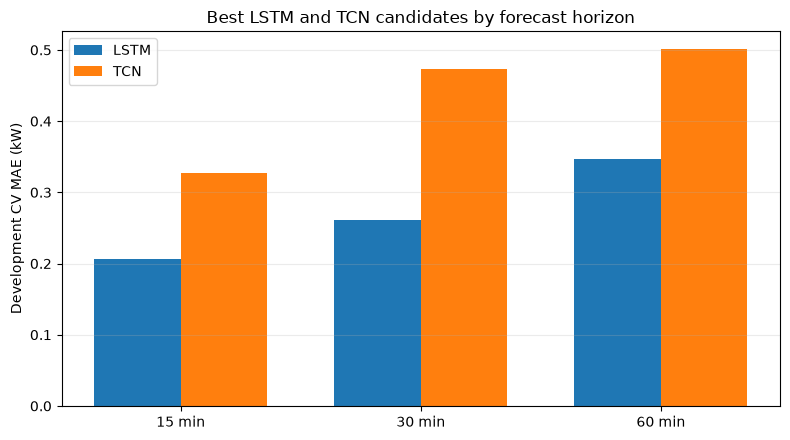

In [30]:
import matplotlib.pyplot as plt

horizon_labels = ["15 min", "30 min", "60 min"]
model_order = ("LSTM", "TCN")
positions = np.arange(len(horizon_labels))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, model in enumerate(model_order):
    model_rows = (selected.loc[selected["model"] == model]
                  .set_index("horizon_minutes").loc[[15, 30, 60]])
    ax.bar(positions + (i - 0.5) * width,
           model_rows["cv_mae_kw"].to_numpy(), width, label=model)
ax.set_xticks(positions, horizon_labels)
ax.set_ylabel("Development CV MAE (kW)")
ax.set_title("Best LSTM and TCN candidates by forecast horizon")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 10. Conclusions and next stage

This notebook completes the planned LSTM and TCN development study. All **360 candidate–fold evaluations** are archived, and the checks above verify their completeness, identities and reported metrics. The results tables identify the strongest development candidates for each horizon and show whether adding the F4 features helped relative to F3.

The interpretation should consider both average accuracy and consistency across folds. In particular, several TCN configurations produced large errors alongside rising training losses. These are genuine outcomes of the fixed experimental settings and remain part of the comparison. A configuration with a competitive average but a very unstable fold should be discussed with that limitation.

The model-selection decision must be recorded from these **development-only** results before any terminal evaluation. The June–August 2019 holdout has not been evaluated here. A later, separate stage can refit the selected configuration using the approved development data and then evaluate the locked holdout once, following the protocol from Notebook 09.

**Reproducibility:** the historical `11_deep_learning_models.ipynb` remains unchanged. This revised notebook reads the versioned V1 and V2 archives and has all training switches set to `False`. No existing CV checkpoint needs to be retrained.

## 11. GRU and BiLSTM extension

The earlier sections complete the 360-fold LSTM and TCN study. This extension adds GRU and bidirectional LSTM (BiLSTM) without changing those archived results. Both recurrent models use the same four layer configurations as LSTM. Each is evaluated across three forecast horizons, five feature families and three chronological folds: another 360 evaluations in total.

The 13-step sequence contains measurements from the hour preceding the forecast issue time. BiLSTM reads this **historical** sequence in both directions; it does not access observations after the issue time. The outer validation periods, inner early-stopping split, 60-minute label embargo, seed, optimizer and evaluation metric remain the same as the earlier neural campaign.

For consistency, F0 uses the original V1 train-only scaling code. F1–F4 use the V2 scaling code, including the year-safe treatment for a constant year in the inner training fold. The new results have their own checkpoint directories. The original LSTM and TCN files are not updated.

**Training remains off during Run All.** To begin a small batch later, change the explicit extension switch in the following cell and run that cell only. The June–August 2019 terminal period is still excluded.


In [48]:
# Read the GRU/BiLSTM archive without starting any training by default.
EXT_RUN_BATCH = False
EXT_MAX_NEW_FITS = 1
EXT_MODELS = ("GRU", "BiLSTM")

from src.revised_recurrent_extension import (
    EXPECTED_FITS as EXT_EXPECTED_FITS,
    F0_ARCHIVE as EXT_F0_ARCHIVE,
    V2_ARCHIVE as EXT_V2_ARCHIVE,
    read_progress as read_recurrent_extension,
    complete_rankings as rank_recurrent_extension,
    run_batch as run_recurrent_extension,
)

assert M2_RUN_PILOTS is False
assert M3_RUN_LSTM is False and M3_RUN_TCN is False
assert M4_RUN_ONE is False and M5_RUN_BATCH is False and M6_RUN_BATCH is False
assert len(m6_final_progress) == 360, "Check the completed original CV archive first"

ext_report = run_recurrent_extension(
    root=PROJECT_ROOT,
    payload_factory=m5_payload_for,
    models=EXT_MODELS,
    max_new_fits=EXT_MAX_NEW_FITS,
    enabled=EXT_RUN_BATCH,
)
print("GRU/BiLSTM DEVELOPMENT CV:", ext_report["after"], "/", EXT_EXPECTED_FITS)
if not EXT_RUN_BATCH:
    assert ext_report["new_fits"] == 0
    print("GRU/BiLSTM BATCH: DISABLED — no training")


GRU/BiLSTM DEVELOPMENT CV: 210 / 360
GRU/BiLSTM BATCH: DISABLED — no training


### Running the additional models

Start with one GRU fit and one BiLSTM fit, in separate batches. After checking that both finish and their checkpoints can be read, continue in batches of about 10–15 fits. The batch runner automatically skips work already archived.

To run the first GRU fit, change `EXT_RUN_BATCH` to `True`, set `EXT_MODELS = ("GRU",)` and `EXT_MAX_NEW_FITS = 1` in the previous cell, then execute **only that cell**. Repeat with `EXT_MODELS = ("BiLSTM",)` for the first BiLSTM fit. Restore `EXT_RUN_BATCH = False` immediately after each batch and save the notebook. Never select Run All while a training switch is on.

Both new archive directories are under `results/development_only/`. A completed fold is recorded as JSON only after the selected number of epochs has been refitted and its outer-fold score has been calculated. If a run is interrupted, its already-completed files can be reused. The new archive has 360 intended records; combining it with the original 360 gives 720 evaluations across all four architectures.


In [32]:
# Read-only comparison; report results only when enough new folds are archived.
from IPython.display import display

ext_scores = read_recurrent_extension(PROJECT_ROOT)
ext_rankings = rank_recurrent_extension(PROJECT_ROOT)
print(f"GRU/BiLSTM completed: {len(ext_scores)}/360 checkpoint records")

if len(ext_scores):
    progress = (ext_scores.groupby(["model", "horizon_minutes"])
                .size().rename("completed_folds").reset_index())
    display(progress)

if not ext_rankings.empty:
    ext_winners = ext_rankings.loc[ext_rankings["rank"] == 1]
    print("Completed GRU/BiLSTM feature-family comparisons (development only)")
    display(ext_winners[["model", "horizon_minutes", "feature_family",
                         "candidate_id", "cv_mae_kw", "cv_rmse_kw"]].round(4))
else:
    print("Full three-fold candidate groups are not available yet.")

if len(ext_scores) == 360:
    assert len(ext_rankings) == 120, "Expected 120 GRU/BiLSTM candidate rankings"
    all_rankings = pd.concat([cv_rankings, ext_rankings], ignore_index=True)
    assert len(all_rankings) == 240
    winners = (all_rankings.sort_values(
        ["model", "horizon_minutes", "cv_mae_kw", "feature_family", "config_index"],
        kind="stable")
        .drop_duplicates(["model", "horizon_minutes"])
        .sort_values(["horizon_minutes", "model"]))
    print("Four-architecture development-CV comparison")
    display(winners[["model", "horizon_minutes", "feature_family",
                     "candidate_id", "cv_mae_kw", "cv_rmse_kw"]].round(4))
else:
    print("Four-architecture comparison will be produced after all 360 additional folds finish.")


GRU/BiLSTM completed: 0/360 checkpoint records
Full three-fold candidate groups are not available yet.
Four-architecture comparison will be produced after all 360 additional folds finish.


### Status of this extension

The original 360 LSTM/TCN folds are complete and remain the reference comparison. The additional GRU/BiLSTM campaign is treated as a separate development-only experiment until its full set of records is available. It is too early to say whether either new model improves the results. Final architecture selection must use the completed three-fold development scores, not the untouched terminal holdout.
